# Intervention full study: what editing SAE features does to the Solver

**The question:** if we edit the features an SAE says are linked to *adopting the Critic's answer*,
does the Solver change its mind more often than if we edit random features of the same size?

**The setup, in three sentences.** For each episode we replay the Solver's second answer (A2) with a
small edit at layer 25, at the final prompt token: the edit moves the activation by r = 0.2 of its norm
along the targeted SAE features, or along matched random features. Claude labels each regenerated A2
as adoption, retention, agreement or out. A **flip** is an answer whose label is the opposite of the
episode's stored label (adoption → retention, or retention → adoption).

**Effect = targeted flip % − random flip %**, in percentage points (pp), paired by episode.

> The figures and tables below are computed from the run folder set in the next cell, so they work for
> any run. The written takeaways describe run `20261106T000808809026Z-02871d677287`; reread them if you
> point the notebook at another run.

## Choose the run

Change `RUN_DIR` to analyse a different run. Everything below reads from that folder's `merge/` output
(written by `run_intervention.py merge`) and saves figures as SVG to `merge/figures/`.

In [1]:
RUN_DIR = "results/intervention_layer25/20261106T000808809026Z-02871d677287"

In [2]:
import json
import os
import re
from pathlib import Path
from types import SimpleNamespace

# Find the repo root so the notebook works from notebooks/intervention/.
ROOT = Path.cwd()
while not (ROOT / "configs" / "intervention").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("Run this notebook from inside the repository.")
    ROOT = ROOT.parent
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

from mas_sae.intervention.analysis.tables import Outcomes
from mas_sae.intervention.experiment.episodes import OPPOSITE

MERGE_DIR = Path(RUN_DIR) / "merge"
FIGURE_DIR = MERGE_DIR / "figures"
if not (MERGE_DIR / "summary.json").is_file():
    raise FileNotFoundError(f"{MERGE_DIR / 'summary.json'} not found: run the merge stage for this run first.")
FIGURE_DIR.mkdir(exist_ok=True)

## Load the merged results

- `summary.json` and the `table_*.csv` files are the pipeline's own results (CIs, p-values, Holm).
- `labeled_rows.jsonl` has one row per regenerated answer, with its Claude label. The notebook uses it
  for the extra checks (sections 5–8). It never calls Claude.

In [3]:
summary = json.loads((MERGE_DIR / "summary.json").read_text())
if summary.get("labels_stubbed"):
    raise RuntimeError("This run's labels are stubbed (smoke run): its numbers are meaningless.")

with open(MERGE_DIR / "labeled_rows.jsonl") as f:
    labeled_rows = [json.loads(line) for line in f]
answers = pd.DataFrame(labeled_rows)
answers["is_flip"] = answers.label == answers.stored_label.map(OPPOSITE)
answers["is_out"] = answers.label == "out"

table_p = pd.read_csv(MERGE_DIR / "table_P_primary.csv")
table_1 = pd.read_csv(MERGE_DIR / "table_1.csv")
table_2_prespecified = pd.read_csv(MERGE_DIR / "table_2_prespecified.csv")
table_2_exploratory = pd.read_csv(MERGE_DIR / "table_2_exploratory.csv")
table_d = pd.read_csv(MERGE_DIR / "table_D_directions.csv")
reference_rows = pd.read_csv(MERGE_DIR / "reference_rows.csv")

analysis_plan = SimpleNamespace(**summary["analysis_plan"])
EDIT_SIZE = summary["edit_size"]
N_RANDOM_DRAWS = int(answers.draw.max()) + 1
N_EPISODES = summary["n_episodes_analysed"]

# Roles: the pre-specified SAEs are the primary family; the exploratory SAE is the one named only in the
# exploratory contrasts; whatever representation is left is the non-SAE control (raw activations).
PRIMARY_SAES = list(analysis_plan.primary_representations)
EXPLORATORY_SAES = sorted({a for a, _ in analysis_plan.exploratory_contrasts} - set(PRIMARY_SAES))
edited_representations = set(answers.loc[answers.kind == "edit", "representation"])
CONTROLS = sorted(edited_representations - set(PRIMARY_SAES) - set(EXPLORATORY_SAES))
ARMS = ["decrease", "increase", "both"]
STRATA = ["adoption", "retention"]

print(f"{N_EPISODES} episodes analysed, {len(summary['excluded_episodes'])} excluded, "
      f"{len(answers):,} labeled answers, r = {EDIT_SIZE}, {N_RANDOM_DRAWS} random draws per condition.")
print("Primary SAEs:", PRIMARY_SAES, "| exploratory:", EXPLORATORY_SAES, "| control:", CONTROLS)

983 episodes analysed, 17 excluded, 63,895 labeled answers, r = 0.2, 3 random draws per condition.
Primary SAEs: ['L1 SAE', 'Pretrained SAE', 'Fine-tuned decoder'] | exploratory: ['Fully fine-tuned'] | control: ['Raw activations']


### Shared style and helpers

Same palette as the choose-r pilot notebook: each SAE keeps its color in every figure, random edits are
neutral gray, and the raw-activation control is dark gray with square markers.

In [4]:
COLOR = {"L1 SAE": "#2a78d6", "Pretrained SAE": "#eb6834", "Fine-tuned decoder": "#1baf7a",
         "Fully fine-tuned": "#8f5ccf", "Raw activations": "#3d3c39"}
MARKER = {name: ("s" if name in CONTROLS else "o") for name in COLOR}
RANDOM_GRAY = "#898781"
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.grid.axis": "x",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 1.6, "lines.markersize": 7,
    "font.size": 10,
    "svg.fonttype": "none",  # keep SVG text as editable text, not paths
})

CI_PATTERN = re.compile(r"([+-]?\d+\.\d+) \[([+-]?\d+\.\d+), ([+-]?\d+\.\d+)\]")


def parse_ci_text(text: str) -> tuple[float, float, float]:
    """'+1.8 [+0.4, +3.3]' -> (1.8, 0.4, 3.3): the pipeline writes Δ and its 95% CI as one string."""
    match = CI_PATTERN.fullmatch(text.strip())
    if match is None:
        raise ValueError(f"Cannot read a Δ [95% CI] from {text!r}.")
    return tuple(float(part) for part in match.groups())


def save_figure(fig, file_stem: str) -> None:
    path = FIGURE_DIR / f"{file_stem}.svg"
    fig.savefig(path, format="svg", bbox_inches="tight")
    print(f"Saved {path}")


def forest_plot(ax, effects: pd.DataFrame, representations: list[str], *, label_column: str = "arm",
                filled_column: str | None = None, annotation_column: str | None = None) -> None:
    """One row per (representation, arm): Δ with its 95% CI, grouped by representation, top to bottom.

    `effects` needs columns representation, arm, delta_pp, ci_low_pp, ci_high_pp. Rows whose
    `filled_column` is False are drawn hollow; `annotation_column` is printed at the right edge.
    """
    row_labels, y = [], 0
    for representation in representations:
        for arm in ARMS:
            row = effects[(effects.representation == representation) & (effects.arm == arm)].iloc[0]
            is_filled = True if filled_column is None else bool(row[filled_column])
            color = COLOR[representation]
            ax.plot([row.ci_low_pp, row.ci_high_pp], [y, y], color=color, linewidth=2, solid_capstyle="butt")
            ax.plot(row.delta_pp, y, marker=MARKER[representation], markersize=8, color=color,
                    markerfacecolor=color if is_filled else "#fcfcfb", markeredgewidth=1.6)
            if annotation_column is not None:
                ax.annotate(row[annotation_column], (1.0, y), xycoords=("axes fraction", "data"),
                            xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK_2)
            row_labels.append(f"{representation} · {row[label_column]}")
            y += 1
        y += 0.6  # gap between representations
    positions = [i + 0.6 * (i // len(ARMS)) for i in range(len(row_labels))]
    ax.set_yticks(positions, row_labels)
    ax.set_ylim(positions[-1] + 0.7, -0.7)
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.grid(axis="y", visible=False)


def add_holm_legend(legend_owner, holm_scope: str, **legend_options) -> None:
    """Explain the marker fill used by forest_plot: filled = survives Holm, hollow = does not.

    `legend_owner` is an Axes, or the Figure when one legend serves several panels.
    """
    filled = Line2D([], [], marker="o", linestyle="none", markersize=8, color=INK_2,
                    label=f"filled: survives Holm correction ({holm_scope}, p(Holm) < 0.05)")
    hollow = Line2D([], [], marker="o", linestyle="none", markersize=8, color=INK_2,
                    markerfacecolor="#fcfcfb", markeredgewidth=1.6, label="hollow: does not survive")
    line = Line2D([], [], color=INK_2, linewidth=2, label="line: 95% bootstrap CI over episodes")
    legend_owner.legend(handles=[filled, hollow, line], **legend_options)


def effects_from_table(table: pd.DataFrame, ci_column: str) -> pd.DataFrame:
    """The pipeline's table with Δ and its CI as numbers, and lower-case representation/arm columns."""
    parsed = table[ci_column].map(parse_ci_text)
    return table.assign(representation=table.Representation, arm=table.Arm,
                        delta_pp=[d for d, _, _ in parsed], ci_low_pp=[lo for _, lo, _ in parsed],
                        ci_high_pp=[hi for _, _, hi in parsed])

## 1. Can we trust the measurement?

Two checks before any effect:

- **Baseline replay:** regenerating A2 with no SAE and no edit should reproduce the stored answer, so
  its flip rate should be about 0%.
- **SAE spliced in, no edit:** replacing the activation with the SAE's reconstruction adds a little
  noise. These flips set the noise floor that every edited condition carries.

In [5]:
reference_table = (reference_rows
                   .pivot_table(index="Condition", columns="Stratum", values="Flip %", sort=False)
                   .round(1))
reference_table.columns = [f"Flip % ({stratum})" for stratum in reference_table.columns]
display(reference_table)

baseline_check = summary["baseline_check"]
exclusion_reasons = pd.Series(summary["excluded_episodes"], dtype=str).value_counts()
print(f"Baseline check passed: {baseline_check['passed']} "
      f"(label match rate {baseline_check['label_match_rate']:.1%} over {baseline_check['n_episodes']} episodes).")
print(f"Excluded episodes: {len(summary['excluded_episodes'])} of {N_EPISODES + len(summary['excluded_episodes'])}")
display(exclusion_reasons.rename("episodes").to_frame())

,Flip % (adoption → retention),Flip % (retention → adoption)
Condition,,
"Baseline (no SAE, no edit)",0.0,0.0
"L1 SAE spliced in, no edit",2.2,2.1
"Pretrained SAE spliced in, no edit",1.6,2.3
"Fine-tuned decoder spliced in, no edit",1.6,1.6
"Fully fine-tuned spliced in, no edit",1.8,1.8


Baseline check passed: True (label match rate 100.0% over 1000 episodes).
Excluded episodes: 17 of 1000


,episodes
labeling failed: missing_field:solver_attempt_2,17


In [6]:
# Which edited conditions produced the empty answers behind the labeling failures?
excluded_ids = set(summary["excluded_episodes"])
shard_answers = pd.concat(pd.read_json(path, lines=True) for path in sorted(Path(RUN_DIR).glob("shard_*.jsonl")))
empty_answers = shard_answers[shard_answers.episode_id.isin(excluded_ids) & (shard_answers.answer.str.strip() == "")]
empty_answers.groupby(["representation", "arm", "source"]).size().rename("empty answers").to_frame()

empty answers
representation     arm      source               
Fine-tuned decoder both     random              2
                   decrease random              1
Fully fine-tuned   both     random              1
Pretrained SAE     decrease random              1
Raw activations    both     random              6
                   decrease random              7
                   increase random              1

**Takeaway:** the replay reproduces every stored answer (0% baseline flips), and splicing an SAE in
without editing flips about 2% of answers. 17 episodes (1.7%) were dropped because an edited answer came
back empty and couldn't be labeled. Every one of those empty answers came from a *random* edit, so the
exclusions don't remove targeted-edit successes.

## 2. ⭐ The main result: targeted edits flip more answers than random edits

This is the pre-registered primary test: 3 SAEs × 3 arms, both strata pooled, one-sided, Holm-corrected
across all 9. Each row is Δ = targeted − random flip rate with its 95% bootstrap CI over episodes.
**Filled** markers survive Holm correction (α = 0.05); hollow ones don't.

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/section02_primary_result_targeted_minus_random_flip_rate_by_sae_and_arm_holm_corrected.svg


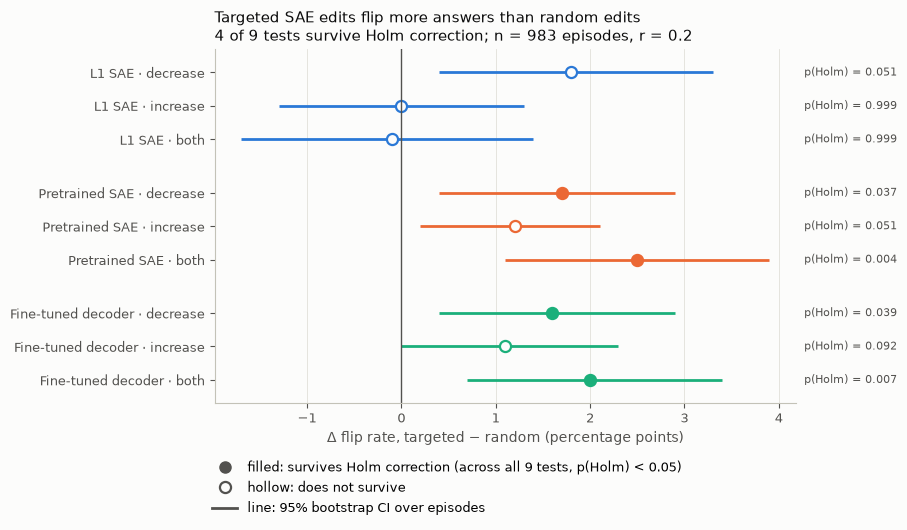

,Representation,Arm,N,Targeted flip %,Random flip % (mean of draws),Δ (pp) [95% CI],p (one-sided),p (Holm),Survives Holm (α = 0.05)
0,L1 SAE,decrease,983,6.714,4.917,"+1.8 [+0.4, +3.3]",0.010,0.051,False
1,L1 SAE,increase,983,5.595,5.561,"+0.0 [-1.3, +1.3]",0.499,0.999,False
2,L1 SAE,both,983,6.409,6.545,"-0.1 [-1.7, +1.4]",0.582,0.999,False
3,Pretrained SAE,decrease,983,5.086,3.425,"+1.7 [+0.4, +2.9]",0.005,0.037,True
4,Pretrained SAE,increase,983,3.866,2.713,"+1.2 [+0.2, +2.1]",0.010,0.051,False
5,Pretrained SAE,both,983,6.205,3.730,"+2.5 [+1.1, +3.9]",0.000,0.004,True
6,Fine-tuned decoder,decrease,983,4.883,3.289,"+1.6 [+0.4, +2.9]",0.006,0.039,True
7,Fine-tuned decoder,increase,983,4.171,3.052,"+1.1 [+0.0, +2.3]",0.031,0.092,False
8,Fine-tuned decoder,both,983,5.595,3.561,"+2.0 [+0.7, +3.4]",0.001,0.007,True


In [7]:
primary_effects = effects_from_table(table_p, "Δ (pp) [95% CI]")
primary_effects["holm_note"] = [f"p(Holm) = {p:.3f}" for p in primary_effects["p (Holm)"]]
n_surviving = int(primary_effects["Survives Holm (α = 0.05)"].sum())

fig, ax = plt.subplots(figsize=(7.5, 4.6))
forest_plot(ax, primary_effects, PRIMARY_SAES,
            filled_column="Survives Holm (α = 0.05)", annotation_column="holm_note")
ax.set_xlabel("Δ flip rate, targeted − random (percentage points)")
add_holm_legend(ax, "across all 9 tests", loc="upper center", bbox_to_anchor=(0.4, -0.13), ncol=1)
ax.set_title(f"Targeted SAE edits flip more answers than random edits\n"
             f"{n_surviving} of 9 tests survive Holm correction; n = {N_EPISODES} episodes, r = {EDIT_SIZE}",
             loc="left")
save_figure(fig, "section02_primary_result_targeted_minus_random_flip_rate_by_sae_and_arm_holm_corrected")
plt.show()

display(table_p.round(3))


# TODO: can we get an explanation of open vs closed circles in this viz?

**Takeaway:** the primary claim holds. The Pretrained SAE and the Fine-tuned decoder flip more answers
with targeted edits than with random ones for "both" (+2.5 and +2.0 pp) and "decrease" (+1.7 and
+1.6 pp). Their "increase" arms are positive too but don't survive correction. L1 SAE "decrease" just
misses (p(Holm) = 0.051), and its other two arms are null.

## 3. How big is that, really?

Δ alone hides the scale. Here are the two flip rates it subtracts: random (gray) and targeted (color),
for each SAE and arm. The line connects the pair for the same condition.

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/section03_absolute_flip_rates_targeted_vs_random_by_sae_and_arm.svg


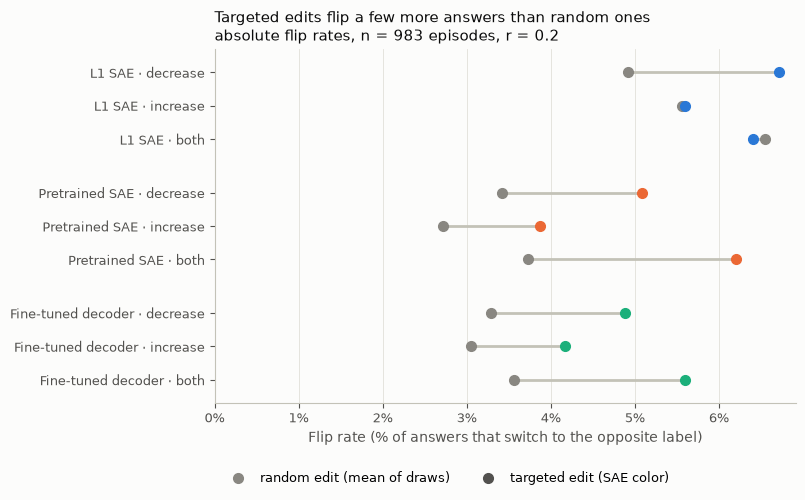

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
row_labels, y = [], 0
for representation in PRIMARY_SAES:
    for arm in ARMS:
        row = table_p[(table_p.Representation == representation) & (table_p.Arm == arm)].iloc[0]
        targeted_pct, random_pct = row["Targeted flip %"], row["Random flip % (mean of draws)"]
        ax.plot([random_pct, targeted_pct], [y, y], color=AXIS, linewidth=2, zorder=1)
        ax.plot(random_pct, y, "o", color=RANDOM_GRAY, zorder=2)
        ax.plot(targeted_pct, y, "o", color=COLOR[representation], zorder=3)
        row_labels.append(f"{representation} · {arm}")
        y += 1
    y += 0.6
positions = [i + 0.6 * (i // len(ARMS)) for i in range(len(row_labels))]
ax.set_yticks(positions, row_labels)
ax.set_ylim(positions[-1] + 0.7, -0.7)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, None)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Flip rate (% of answers that switch to the opposite label)")
ax.plot([], [], "o", color=RANDOM_GRAY, label="random edit (mean of draws)")
ax.plot([], [], "o", color=INK_2, label="targeted edit (SAE color)")
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.16), ncol=2)
ax.set_title(f"Targeted edits flip a few more answers than random ones\n"
             f"absolute flip rates, n = {N_EPISODES} episodes, r = {EDIT_SIZE}", loc="left")
save_figure(fig, "section03_absolute_flip_rates_targeted_vs_random_by_sae_and_arm")
plt.show()

**Takeaway:** targeted edits flip about 4–6% of answers; random edits of the same size flip about 3–4%.
The edits **nudge** the decision; they don't control it. Most answers don't change at all under either kind.

## 4. Which way is easier to push?

The two strata, split. **Adoption → retention:** the Solver had adopted the Critic's answer, and we try
to make it keep its own. **Retention → adoption:** the reverse. The arm names are relative to the
stratum: in adoption → retention, "decrease" means *decrease adoption features* and "increase" means
*increase retention features*. Filled markers have p(Holm) < 0.05, corrected within each SAE's 6 rows
(two-sided; secondary analysis).

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/section04_targeted_minus_random_by_stratum_adoption_to_retention_vs_retention_to_adoption.svg


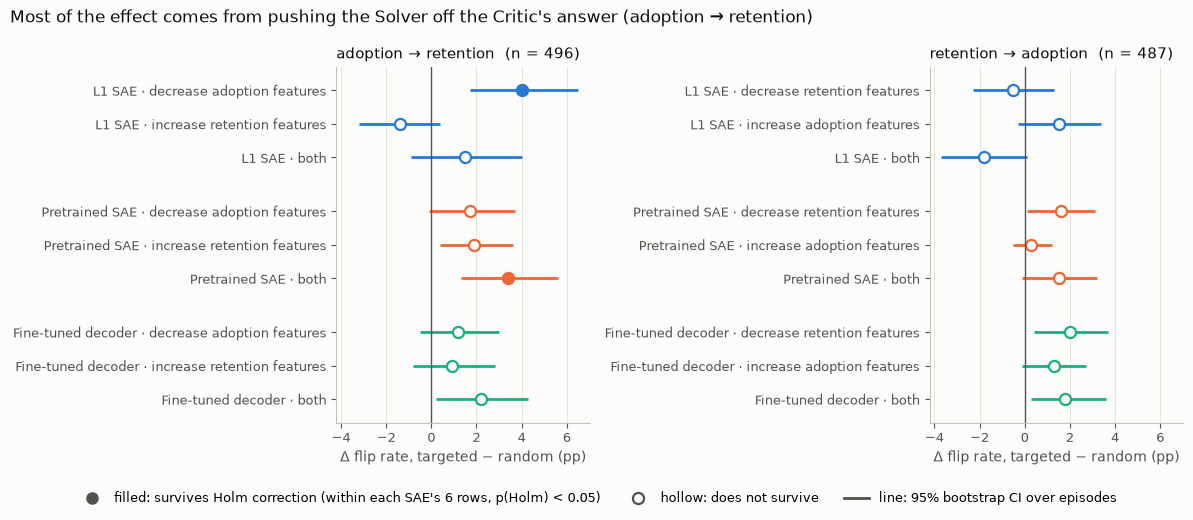

,mean Δ over the 9 SAE × arm rows (pp)
Stratum (baseline → target),
adoption → retention,1.71
retention → adoption,0.86


In [9]:
per_stratum_effects = effects_from_table(table_1, "Δ (pp) [95% CI]")
per_stratum_effects["representation"] = per_stratum_effects.Representation.str.rstrip(" †")
per_stratum_effects["arm_label"] = per_stratum_effects.Arm
per_stratum_effects["arm"] = per_stratum_effects.Arm.map(
    lambda name: "both" if name == "both" else name.split()[0])  # "decrease adoption features" -> "decrease"
per_stratum_effects["survives_holm"] = per_stratum_effects["p (Holm)"] < 0.05

strata_names = list(dict.fromkeys(per_stratum_effects["Stratum (baseline → target)"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for ax, stratum_name in zip(axes, strata_names):
    stratum_effects = per_stratum_effects[per_stratum_effects["Stratum (baseline → target)"] == stratum_name]
    forest_plot(ax, stratum_effects, PRIMARY_SAES, label_column="arm_label", filled_column="survives_holm")
    n = int(stratum_effects.N.iloc[0])
    ax.set_title(f"{stratum_name}  (n = {n})", loc="left")
    ax.set_xlabel("Δ flip rate, targeted − random (pp)")
axes[1].tick_params(axis="y", labelleft=True)
fig.suptitle("Most of the effect comes from pushing the Solver off the Critic's answer (adoption → retention)",
             x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
add_holm_legend(fig, "within each SAE's 6 rows", loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3)
save_figure(fig, "section04_targeted_minus_random_by_stratum_adoption_to_retention_vs_retention_to_adoption")
plt.show()

pooled_by_stratum = (per_stratum_effects[per_stratum_effects.representation.isin(PRIMARY_SAES)]
                     .groupby("Stratum (baseline → target)", sort=False).delta_pp.mean().round(2))
display(pooled_by_stratum.rename("mean Δ over the 9 SAE × arm rows (pp)").to_frame())

**Takeaway:** most of the effect is in **adoption → retention**. There, Pretrained "both" (+3.4 pp) and
L1 "decrease adoption features" (+4.0 pp) survive correction; in retention → adoption no SAE row does
(mean Δ across the 9 SAE rows: +1.7 vs +0.9 pp).
Pushing the Solver away from the Critic's answer looks easier than pulling it toward it. That is
descriptive: no pre-specified test compares the two strata. Note that the strata were pooled for the primary test because the two arms are mirror images.

## 5. How do the SAEs compare to editing raw activations?

The control edits directions found directly in the raw layer-25 activations, with no SAE. It is not part
of the pre-registered family, so this figure recomputes every pooled Δ with the pipeline's own test
(`Outcomes`, same bootstrap and seed). The first cell checks that this recomputation reproduces Table P
exactly for the SAEs.

In [10]:
outcomes = Outcomes(labeled_rows, EDIT_SIZE, N_RANDOM_DRAWS, analysis_plan)
all_episodes = outcomes.episodes()


def pooled_effect(representation: str, arm: str) -> dict:
    """Δ targeted − random with both strata pooled, using the pipeline's paired bootstrap (95% CI)."""
    result = outcomes.test(outcomes.targeted(representation, arm, all_episodes),
                           outcomes.random(representation, arm, all_episodes), "two-sided")
    ci_low_pp, ci_high_pp = result["ci95_pp"]
    return {"representation": representation, "arm": arm, "delta_pp": result["delta_pp"],
            "ci_low_pp": ci_low_pp, "ci_high_pp": ci_high_pp}


comparison_representations = PRIMARY_SAES + CONTROLS
pooled_effects = pd.DataFrame([pooled_effect(rep, arm) for rep in comparison_representations for arm in ARMS])

# The recomputation must match the pipeline's Table P (same rounding as its text column).
for _, row in primary_effects.iterrows():
    recomputed = pooled_effects[(pooled_effects.representation == row.representation) & (pooled_effects.arm == row.arm)].iloc[0]
    for column in ["delta_pp", "ci_low_pp", "ci_high_pp"]:
        if round(recomputed[column], 1) != row[column]:
            raise AssertionError(f"{row.representation} {row.arm} {column}: {recomputed[column]:.2f} vs Table P {row[column]}")
print("Recomputed Δ and CIs match Table P for every SAE × arm.")

Recomputed Δ and CIs match Table P for every SAE × arm.


Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/section05_sae_features_vs_raw_activation_control_targeted_minus_random_flip_rate.svg


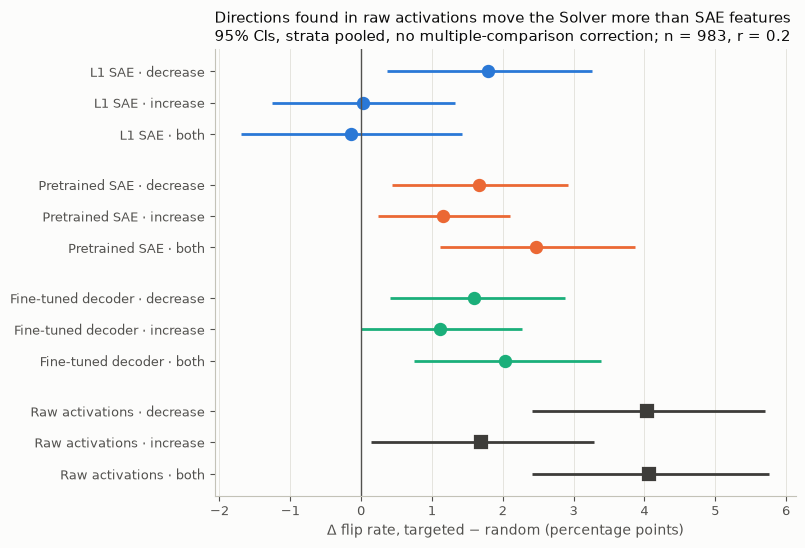

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 5.8))
forest_plot(ax, pooled_effects, comparison_representations)
ax.set_xlabel("Δ flip rate, targeted − random (percentage points)")
ax.set_title(f"Directions found in raw activations move the Solver more than SAE features\n"
             f"95% CIs, strata pooled, no multiple-comparison correction; n = {N_EPISODES}, r = {EDIT_SIZE}",
             loc="left")
save_figure(fig, "section05_sae_features_vs_raw_activation_control_targeted_minus_random_flip_rate")
plt.show()

**Takeaway (the honest part):** raw-activation directions beat random edits by more than any SAE does
(up to about +4 pp pooled, +6.2 pp in adoption → retention). So the data support "SAE features carry
causal signal about adoption", **not** "SAEs isolate the mechanism better than the raw activations".
The positive reading: the SAE features are a named, interpretable handful that recovers a meaningful part
of what the unconstrained raw direction can do. Section 6 checks whether garbled answers inflate the raw
control's number.

## 6. Is the effect robust?

### 6a. Is it a few unstable episodes?

In the choose-r pilot, 3 episodes produced 70% of the flips. Here, for every episode, we count in how
many of the 9 primary targeted conditions (3 SAEs × 3 arms) it flipped, next to the same count for one
random draw (draw 0) of the same 9 conditions.

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/section06a_flips_per_episode_across_9_sae_arm_conditions_targeted_vs_random.svg


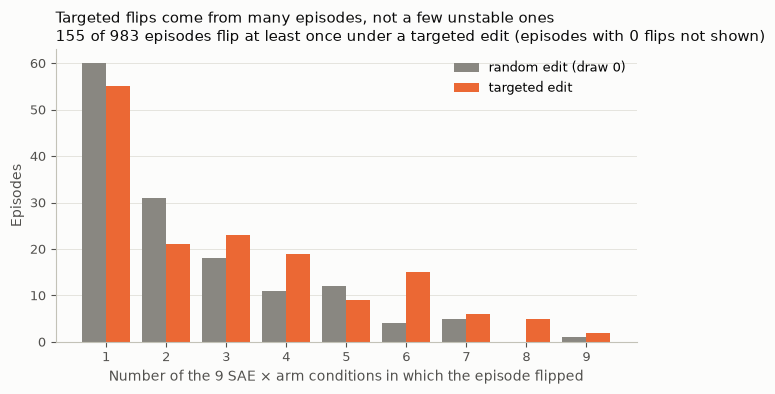

Share of all targeted flips from the 3 most-flipping episodes: 5.5% (pilot: about 70%)


In [12]:
primary_edits = answers[(answers.kind == "edit") & answers.representation.isin(PRIMARY_SAES)]
targeted_flip_counts = (primary_edits[primary_edits.source == "targeted"]
                        .groupby("episode_id").is_flip.sum().astype(int))
random_draw0_flip_counts = (primary_edits[(primary_edits.source == "random") & (primary_edits.draw == 0)]
                            .groupby("episode_id").is_flip.sum().astype(int))

max_count = len(PRIMARY_SAES) * len(ARMS)
count_range = range(1, max_count + 1)  # leave out 0 flips: most episodes never flip and would dwarf the rest
targeted_histogram = targeted_flip_counts.value_counts().reindex(count_range, fill_value=0)
random_histogram = random_draw0_flip_counts.value_counts().reindex(count_range, fill_value=0)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
bar_width = 0.4
ax.bar(np.array(count_range) - bar_width / 2, random_histogram.values, bar_width, color=RANDOM_GRAY, label="random edit (draw 0)")
ax.bar(np.array(count_range) + bar_width / 2, targeted_histogram.values, bar_width, color=COLOR["Pretrained SAE"], label="targeted edit")
ax.set_xticks(list(count_range))
ax.set_xlabel(f"Number of the {max_count} SAE × arm conditions in which the episode flipped")
ax.set_ylabel("Episodes")
ax.grid(axis="x", visible=False)
ax.grid(axis="y", visible=True)
ax.legend()
n_flipping_targeted = int((targeted_flip_counts > 0).sum())
ax.set_title(f"Targeted flips come from many episodes, not a few unstable ones\n"
             f"{n_flipping_targeted} of {N_EPISODES} episodes flip at least once under a targeted edit "
             f"(episodes with 0 flips not shown)", loc="left")
save_figure(fig, "section06a_flips_per_episode_across_9_sae_arm_conditions_targeted_vs_random")
plt.show()

top3_share = targeted_flip_counts.sort_values(ascending=False).head(3).sum() / targeted_flip_counts.sum()
print(f"Share of all targeted flips from the 3 most-flipping episodes: {top3_share:.1%} (pilot: about 70%)")

### 6b. Do "out" answers distort the comparison?

An **out** answer (neither adoption nor retention, often garbled) can't flip. If one kind of edit garbles
more answers, its flip rate drops for a reason unrelated to adoption. So here the flip rate is computed
among answers that **aren't out**, for targeted and random, with a 95% bootstrap CI that resamples
episodes (10,000 resamples). Small vertical ticks show the original Δ over all answers (section 5).

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/section06b_targeted_minus_random_flip_rate_among_non_out_answers_with_bootstrap_ci.svg


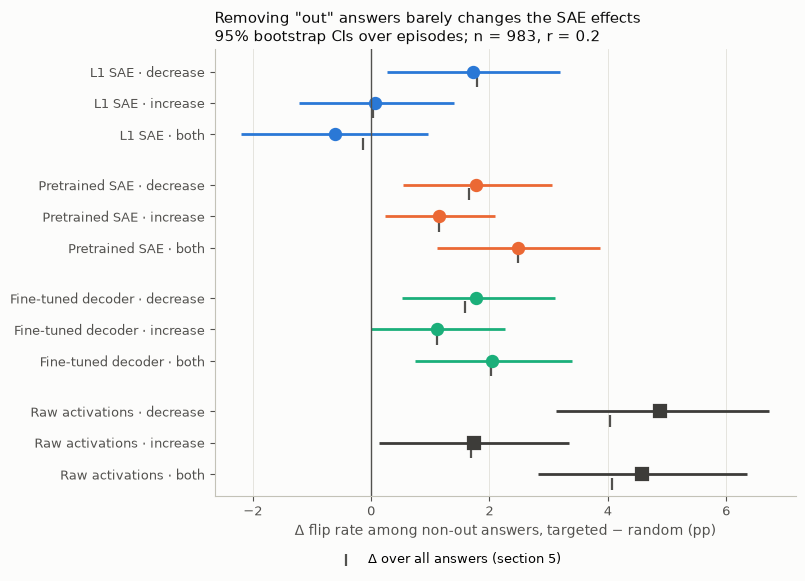

,representation,arm,delta_pp_all_answers,delta_pp_non_out,ci_low_pp,ci_high_pp,targeted_out_pct,random_out_pct
0,L1 SAE,decrease,1.80,1.72,0.26,3.20,1.12,3.02
1,L1 SAE,increase,0.03,0.07,-1.22,1.40,1.73,1.05
2,L1 SAE,both,-0.14,-0.61,-2.20,0.97,0.20,6.88
3,Pretrained SAE,decrease,1.66,1.78,0.54,3.06,2.64,0.58
4,Pretrained SAE,increase,1.15,1.14,0.23,2.09,0.00,0.31
5,Pretrained SAE,both,2.48,2.48,1.11,3.88,0.41,0.68
6,Fine-tuned decoder,decrease,1.59,1.77,0.53,3.10,3.87,0.58
7,Fine-tuned decoder,increase,1.12,1.11,-0.01,2.27,0.00,0.24
8,Fine-tuned decoder,both,2.03,2.05,0.75,3.40,0.71,0.78
9,Raw activations,decrease,4.04,4.88,3.12,6.73,10.07,1.53


In [13]:
BOOTSTRAP_SEED = 0


def non_out_flip_effect(representation: str, arm: str) -> dict:
    """Δ in flip rate among non-out answers, targeted − random, with a 95% CI from resampling episodes.

    Each rate is a ratio (flips / non-out answers), so it is recomputed on each resample rather than
    averaged per episode: episodes whose answers are all out then carry no weight, as they should.
    """
    condition = answers[(answers.kind == "edit") & (answers.representation == representation) & (answers.arm == arm)]
    per_episode = (condition.assign(is_valid=~condition.is_out)
                   .groupby(["episode_id", "source"])[["is_flip", "is_valid"]].sum()
                   .unstack("source").reindex(all_episodes))
    targeted_flips, targeted_valid = per_episode[("is_flip", "targeted")].to_numpy(), per_episode[("is_valid", "targeted")].to_numpy()
    random_flips, random_valid = per_episode[("is_flip", "random")].to_numpy(), per_episode[("is_valid", "random")].to_numpy()

    def delta_pp(rows):
        return 100 * (targeted_flips[rows].sum(axis=-1) / targeted_valid[rows].sum(axis=-1)
                      - random_flips[rows].sum(axis=-1) / random_valid[rows].sum(axis=-1))

    rng = np.random.default_rng(BOOTSTRAP_SEED)
    resampled = rng.integers(0, len(all_episodes), size=(analysis_plan.n_bootstrap, len(all_episodes)))
    ci_low_pp, ci_high_pp = np.quantile(delta_pp(resampled), [0.025, 0.975])
    return {"representation": representation, "arm": arm, "delta_pp": float(delta_pp(np.arange(len(all_episodes)))),
            "ci_low_pp": float(ci_low_pp), "ci_high_pp": float(ci_high_pp),
            "targeted_out_pct": 100 * (1 - targeted_valid.sum() / len(all_episodes)),
            "random_out_pct": 100 * (1 - random_valid.sum() / (N_RANDOM_DRAWS * len(all_episodes)))}


non_out_effects = pd.DataFrame([non_out_flip_effect(rep, arm) for rep in comparison_representations for arm in ARMS])

fig, ax = plt.subplots(figsize=(7.5, 5.8))
forest_plot(ax, non_out_effects, comparison_representations)
row_positions = [i + 0.6 * (i // len(ARMS)) for i in range(len(pooled_effects))]
ax.scatter(pooled_effects.delta_pp, np.array(row_positions) + 0.3, marker="|", s=80, color=INK_2,
           label="Δ over all answers (section 5)")
ax.set_xlabel("Δ flip rate among non-out answers, targeted − random (pp)")
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.1))
ax.set_title("Removing \"out\" answers barely changes the SAE effects\n"
             f"95% bootstrap CIs over episodes; n = {N_EPISODES}, r = {EDIT_SIZE}", loc="left")
save_figure(fig, "section06b_targeted_minus_random_flip_rate_among_non_out_answers_with_bootstrap_ci")
plt.show()

comparison = non_out_effects.merge(pooled_effects[["representation", "arm", "delta_pp"]],
                                   on=["representation", "arm"], suffixes=("_non_out", "_all_answers"))
display(comparison[["representation", "arm", "delta_pp_all_answers", "delta_pp_non_out", "ci_low_pp", "ci_high_pp",
                    "targeted_out_pct", "random_out_pct"]].round(2))

**Takeaway:** the targeted flips are spread across about 60 different episodes per condition, and the
3 most-flipping episodes account for only a small share of all targeted flips, unlike the pilot. Removing
out answers leaves the SAE effects about where they were; the raw control's "decrease" arm garbles
about 10% of its targeted answers, so its effect among the answers it doesn't garble is, if anything,
larger.

## 7. Do the edits break the model?

The share of answers labeled **out**, for targeted and random edits. A good edit changes the decision
without garbling the answer.

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/section07_out_answer_rate_targeted_vs_random_by_representation_and_arm.svg


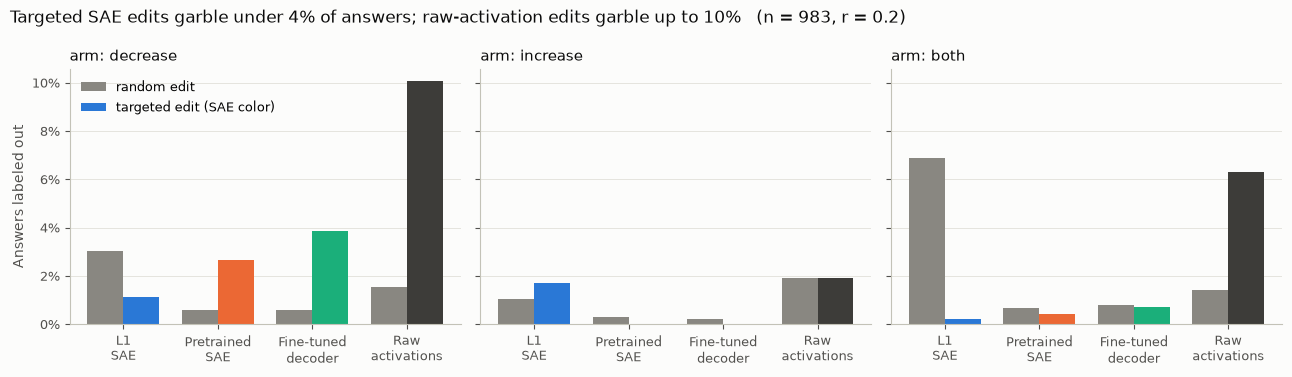

In [14]:
edit_answers = answers[(answers.kind == "edit") & answers.representation.isin(comparison_representations)]
out_pct = (edit_answers.groupby(["representation", "arm", "source"]).is_out.mean() * 100).rename("out_pct")

fig, axes = plt.subplots(1, len(ARMS), figsize=(13, 3.8), sharey=True)
bar_width = 0.38
x = np.arange(len(comparison_representations))
for ax, arm in zip(axes, ARMS):
    random_values = [out_pct[(rep, arm, "random")] for rep in comparison_representations]
    targeted_values = [out_pct[(rep, arm, "targeted")] for rep in comparison_representations]
    ax.bar(x - bar_width / 2, random_values, bar_width, color=RANDOM_GRAY, label="random edit")
    ax.bar(x + bar_width / 2, targeted_values, bar_width, color=[COLOR[rep] for rep in comparison_representations],
           label="targeted edit (SAE color)")
    ax.set_xticks(x, [rep.replace(" ", "\n", 1) for rep in comparison_representations])
    ax.set_title(f"arm: {arm}", loc="left")
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=True)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
axes[0].set_ylabel("Answers labeled out")
axes[0].legend(loc="upper left")
fig.suptitle(f"Targeted SAE edits garble under 4% of answers; raw-activation edits garble up to 10%   (n = {N_EPISODES}, r = {EDIT_SIZE})",
             x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
save_figure(fig, "section07_out_answer_rate_targeted_vs_random_by_representation_and_arm")
plt.show()

**Takeaway:** targeted SAE edits keep out answers below about 4%. The raw control's targeted
"decrease" edit garbles about 10%, and L1 SAE's *random* "both" edits garble about 7%. One thing to
note: targeted "decrease" edits of the Pretrained SAE and Fine-tuned decoder garble more than their
random edits (about 3–4% vs under 1%). Out answers can't flip, so this works *against* the targeted
effect; section 6b shows the effect holds when they're removed. The SAE effects come from changed
decisions, not broken answers.

## 8. Why is the effect small?

How sure the Solver was of its baseline answer, measured as the probability of its first answer token,
against how often edits flip that episode. Each bar pools the 9 primary SAE × arm conditions; error bars
are 95% bootstrap CIs over episodes.

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/section08_flip_rate_by_baseline_first_token_confidence_targeted_vs_random.svg


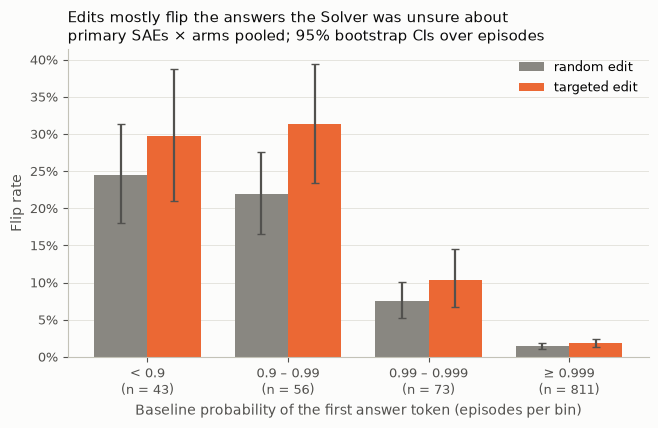

In [15]:
CONFIDENCE_BINS = [0, 0.9, 0.99, 0.999, 1.0001]
CONFIDENCE_LABELS = ["< 0.9", "0.9 – 0.99", "0.99 – 0.999", "≥ 0.999"]


def bootstrap_mean_ci(values: np.ndarray) -> tuple[float, float]:
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    means = values[rng.integers(0, len(values), size=(analysis_plan.n_bootstrap, len(values)))].mean(axis=1)
    return tuple(np.quantile(means, [0.025, 0.975]))


baseline_confidence = (answers[answers.kind == "baseline"].set_index("episode_id")
                       .first_token_logprob.pipe(np.exp).rename("first_token_probability"))
episode_flip_rates = (primary_edits.groupby(["episode_id", "source"]).is_flip.mean().unstack("source") * 100)
episode_flip_rates = episode_flip_rates.join(baseline_confidence)
episode_flip_rates["confidence_bin"] = pd.cut(episode_flip_rates.first_token_probability, CONFIDENCE_BINS,
                                              labels=CONFIDENCE_LABELS, right=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
bar_width = 0.38
x = np.arange(len(CONFIDENCE_LABELS))
for offset, source, color in [(-bar_width / 2, "random", RANDOM_GRAY), (bar_width / 2, "targeted", COLOR["Pretrained SAE"])]:
    means, lows, highs = [], [], []
    for label in CONFIDENCE_LABELS:
        values = episode_flip_rates.loc[episode_flip_rates.confidence_bin == label, source].to_numpy()
        low, high = bootstrap_mean_ci(values)
        means.append(values.mean()); lows.append(low); highs.append(high)
    means = np.array(means)
    ax.bar(x + offset, means, bar_width, color=color, label=f"{source} edit",
           yerr=[means - np.array(lows), np.array(highs) - means], ecolor=INK_2, capsize=3)
episodes_per_bin = episode_flip_rates.confidence_bin.value_counts().reindex(CONFIDENCE_LABELS)
ax.set_xticks(x, [f"{label}\n(n = {n})" for label, n in episodes_per_bin.items()])
ax.set_xlabel("Baseline probability of the first answer token (episodes per bin)")
ax.set_ylabel("Flip rate")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.grid(axis="y", visible=True)
ax.legend()
ax.set_title("Edits mostly flip the answers the Solver was unsure about\n"
             "primary SAEs × arms pooled; 95% bootstrap CIs over episodes", loc="left")
save_figure(fig, "section08_flip_rate_by_baseline_first_token_confidence_targeted_vs_random")
plt.show()

**Takeaway:** most episodes sit in the top confidence bin, where neither kind of edit moves much.
The flips, and the targeted-over-random gap, live in the less confident episodes. A single small edit at
one token has little room to work against a model that is over 99.9% sure, which is why the overall
effect is a few points rather than tens.

## 9. Exploratory: the fully fine-tuned SAE †

Not part of the pre-registered family, so no claim rests on it. Δ per arm, strata pooled, with the
same recomputation as section 5, next to the Pretrained SAE it was fine-tuned from.

Saved results/intervention_layer25/20261106T000808809026Z-02871d677287/merge/figures/section09_exploratory_fully_fine_tuned_sae_vs_pretrained_targeted_minus_random_flip_rate.svg


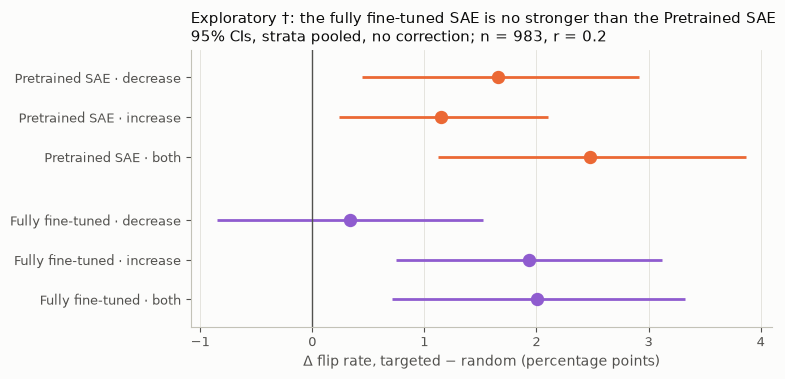

,Family,Contrast (A vs. B),Arm,N,Δ_A − Δ_B (pp) [95% CI],p,p (Holm)
0,exploratory †,Fully fine-tuned vs. Pretrained SAE,decrease,983,"-1.3 [-2.8, +0.1]",0.095690,0.287071
1,exploratory †,Fully fine-tuned vs. Pretrained SAE,increase,983,"+0.8 [-0.6, +2.2]",0.297270,0.594541
2,exploratory †,Fully fine-tuned vs. Pretrained SAE,both,983,"-0.5 [-2.0, +1.1]",0.581042,0.594541


In [16]:
exploratory_representations = ["Pretrained SAE"] + EXPLORATORY_SAES
exploratory_effects = pd.DataFrame([pooled_effect(rep, arm) for rep in exploratory_representations for arm in ARMS])

fig, ax = plt.subplots(figsize=(7.5, 3.6))
forest_plot(ax, exploratory_effects, exploratory_representations)
ax.set_xlabel("Δ flip rate, targeted − random (percentage points)")
ax.set_title(f"Exploratory †: the fully fine-tuned SAE is no stronger than the Pretrained SAE\n"
             f"95% CIs, strata pooled, no correction; n = {N_EPISODES}, r = {EDIT_SIZE}", loc="left")
save_figure(fig, "section09_exploratory_fully_fine_tuned_sae_vs_pretrained_targeted_minus_random_flip_rate")
plt.show()

display(table_2_exploratory)

**Takeaway:** the fully fine-tuned SAE is similar for "increase" and "both" and weaker for "decrease"
(+0.3 vs +1.7 pp), and no contrast between them is significant. Fine-tuning the whole SAE didn't make
its features more causal.

## 10. What we can and can't claim

Each verdict below is computed from this run's tables, so it updates if you change the run.

In [17]:
best_primary = primary_effects.loc[primary_effects.delta_pp.idxmax()]
best_control = pooled_effects[pooled_effects.representation.isin(CONTROLS)].delta_pp.max()
best_sae = pooled_effects[pooled_effects.representation.isin(PRIMARY_SAES)].delta_pp.max()
significant_sae_contrasts = table_2_prespecified[table_2_prespecified["p (Holm)"] < 0.05]
significant_arm_contrasts = table_d[table_d.Representation.isin(PRIMARY_SAES) & (table_d["p (Holm)"] < 0.05)]
stratum_means = pooled_by_stratum.to_dict()
first_stratum, second_stratum = list(stratum_means)


def verdict(is_supported: bool) -> str:
    return "✅ yes" if is_supported else "❌ no"


claims = pd.DataFrame([
    {"Claim": "Some pre-specified SAE's features are causal for adoption (primary test)",
     "Supported?": verdict(summary["primary"]["claim_holds"]),
     "Evidence": f"{n_surviving} of 9 SAE × arm tests survive Holm; largest Δ = {best_primary.delta_pp:+.1f} pp "
                 f"({best_primary.representation}, {best_primary.arm})"},
    {"Claim": "The effect is large",
     "Supported?": verdict(best_primary.delta_pp >= 5),
     "Evidence": f"Largest SAE Δ is {best_primary.delta_pp:+.1f} pp on a random flip rate of a few percent"},
    {"Claim": "SAE features beat raw-activation directions",
     "Supported?": verdict(best_sae > best_control),
     "Evidence": f"Best pooled Δ: SAE {best_sae:+.1f} pp vs raw activations {best_control:+.1f} pp"},
    {"Claim": "One pre-specified SAE beats another",
     "Supported?": verdict(len(significant_sae_contrasts) > 0),
     "Evidence": f"{len(significant_sae_contrasts)} of {len(table_2_prespecified)} between-SAE contrasts survive Holm"},
    {"Claim": "One arm (decrease / increase / both) beats another",
     "Supported?": verdict(len(significant_arm_contrasts) > 0),
     "Evidence": f"{len(significant_arm_contrasts)} of {len(table_d[table_d.Representation.isin(PRIMARY_SAES)])} "
                 f"within-SAE arm contrasts survive Holm"},
    {"Claim": f"The effect is larger for {first_stratum} than for {second_stratum}",
     "Supported?": "descriptive only",
     "Evidence": f"Mean Δ {stratum_means[first_stratum]:+.2f} vs {stratum_means[second_stratum]:+.2f} pp "
                 f"(no pre-specified test of the difference)"},
])
with pd.option_context("display.max_colwidth", None):
    display(claims)

,Claim,Supported?,Evidence
0,Some pre-specified SAE's features are causal for adoption (primary test),✅ yes,"4 of 9 SAE × arm tests survive Holm; largest Δ = +2.5 pp (Pretrained SAE, both)"
1,The effect is large,❌ no,Largest SAE Δ is +2.5 pp on a random flip rate of a few percent
2,SAE features beat raw-activation directions,❌ no,Best pooled Δ: SAE +2.5 pp vs raw activations +4.1 pp
3,One pre-specified SAE beats another,❌ no,0 of 9 between-SAE contrasts survive Holm
4,One arm (decrease / increase / both) beats another,❌ no,0 of 9 within-SAE arm contrasts survive Holm
5,The effect is larger for adoption → retention than for retention → adoption,descriptive only,Mean Δ +1.71 vs +0.86 pp (no pre-specified test of the difference)


**In one sentence, for the write-up:** at layer 25, editing pre-specified Pretrained-SAE and
Fine-tuned-decoder features at the final prompt token shifts the Solver's adoption decision in the
intended direction more than matched random edits do (+1.6 to +2.5 pp, Holm-corrected), mostly by pulling
it away from the Critic's answer; the effect is small, and directions found directly in raw activations
shift it more.

## 11. Limitations and next steps

**What this design can't tell us**
- **One token, one layer, one size.** The edit is applied once, at the final prompt token, at layer 25,
  with r = 0.2. Generated tokens are never edited, so the model can still copy the Critic's answer from
  the unedited prompt tokens. The effect is a lower bound for these features, not their full influence.
- **A very confident model.** Most baselines are above 99.9% sure of their first token (section 8),
  which caps how much any single small edit can move.
- **Raw activations are a ceiling, not a failure.** They aren't sparse or interpretable; the SAE
  question is how much of that ceiling a few named features recover.
- **17 episodes (1.7%) excluded** for empty edited answers, all from random edits (section 1).

**Next steps**
1. Steer at every generated token as a separate, pre-specified family with its own choose-r. Now that
   the final-token effect is positive, this asks how far the same features can push.
2. Add the difference-of-means direction as a second control, to place the SAEs between "random" and
   "best simple direction".
3. Count empty edited answers as "out" in the labeler instead of excluding the episode.